In [36]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.svm import SVC

from sklearn.model_selection import train_test_split
from sklearn.metrics import accuracy_score, confusion_matrix, classification_report, RocCurveDisplay
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler

In [13]:
df = pd.read_csv('databasev4_2.csv')
X = df.drop(columns=['soil_type','radius','pos_x','pos_y','presence'])

na = ["a_rel_10mm","a_rel_20mm","a_rel_30mm","a_rel_40mm","eco2_atraso","eco2_razao"]
X = X.drop(columns=na)

Y = df['presence']

X_train, X_test, y_train, y_test = train_test_split(X,Y,test_size=0.2,random_state=42,stratify=Y)

In [ ]:
accuracy = []
for c in np.arange(0.1,10.1,0.2):    
    svm = Pipeline([
            ('scaler', StandardScaler()),
            ('model', SVC(kernel='rbf', C=c, gamma='scale', probability=True, random_state=42))])

    svm.fit(X_train, y_train)
    y_pred = svm.predict(X_test)
    accuracy.append(accuracy_score(y_test, y_pred))

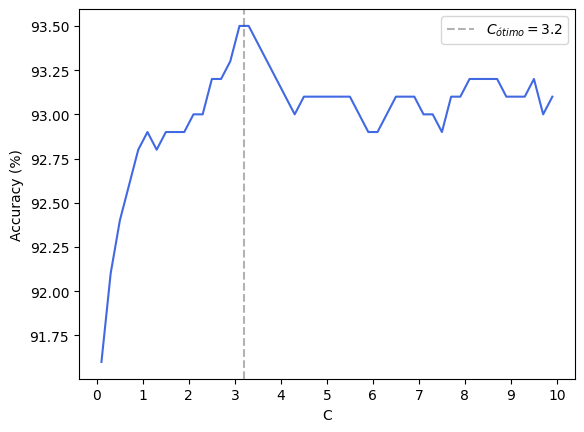

[3.1 3.3]


In [33]:
accuracy = np.array(accuracy)

fig, ax = plt.subplots(1,1)

plt.xlabel('C')
plt.ylabel('Accuracy (%)')
plt.plot(np.arange(0.1,10.1,0.2),accuracy*100,color='royalblue')
plt.axvline(x=3.2,color='black',ls='--',alpha=0.3,label=r'$C_{ótimo} = 3.2$')
plt.xticks(np.arange(0,11,1))
plt.legend()
plt.show()

C = np.arange(0.1,10.1,0.2)
print(C[accuracy==accuracy.max()])

Acurácia: 0.935


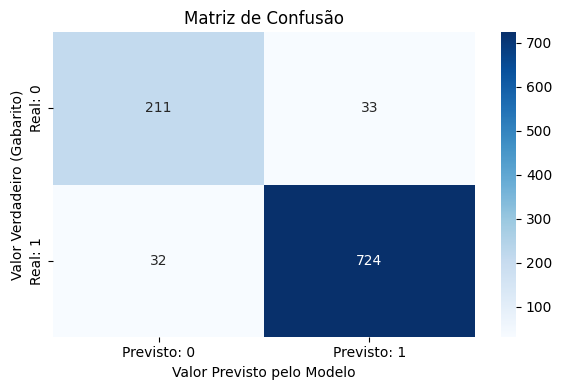


Relatório:
              precision    recall  f1-score   support

           0       0.87      0.86      0.87       244
           1       0.96      0.96      0.96       756

    accuracy                           0.94      1000
   macro avg       0.91      0.91      0.91      1000
weighted avg       0.93      0.94      0.93      1000



c:\Users\User\AppData\Local\Programs\Python\Python310\lib\site-packages\sklearn\utils\_plotting.py:175: FutureWarning: `**kwargs` is deprecated and will be removed in 1.9. Pass all matplotlib arguments to `curve_kwargs` as a dictionary instead.
  warnings.warn(


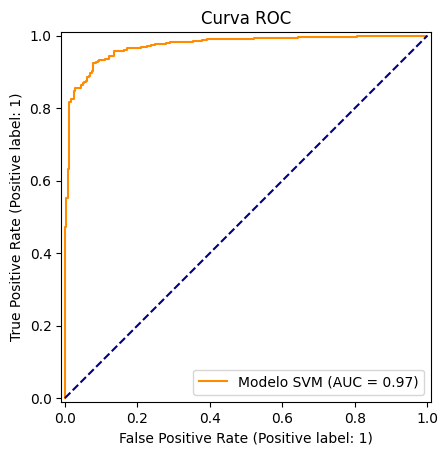

In [ ]:
svm = Pipeline([
        ('scaler', StandardScaler()),
        ('model', SVC(kernel='rbf', C=3.2, gamma='scale', probability=True, random_state=42))])

svm.fit(X_train, y_train)
y_pred = svm.predict(X_test)

print("Acurácia:", accuracy_score(y_test,y_pred))
matriz_c = confusion_matrix(y_test,y_pred)
plt.figure(figsize=(6, 4))
sns.heatmap(matriz_c, annot=True, fmt='d', cmap='Blues', 
            xticklabels=['Previsto: 0', 'Previsto: 1'], 
            yticklabels=['Real: 0', 'Real: 1'])

plt.title('Matriz de Confusão')
plt.ylabel('Valor Verdadeiro (Gabarito)')
plt.xlabel('Valor Previsto pelo Modelo')
plt.tight_layout()
plt.show()
print("\nRelatório:")
print(classification_report(y_test,y_pred))
RocCurveDisplay.from_estimator(svm, X_test, y_test, name="Modelo SVM",color="darkorange")
plt.plot([0, 1], [0, 1], color="navy", linestyle="--")
plt.title("Curva ROC")
plt.show()
